# Packages and definitions

In [6]:
import pandas as pd
import glob
import anndata as ad
import numpy as np 
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import pathlib
import json
import os
from adjustText import adjust_text
import math

start_map = {
    'K15357-10': 85,
    'K11178-10': 18,
    'K19044-13': 45
}

architecture_order = ['solid', 'glandular dense', 'glandular', 'glandular infiltrated', 'budding', 'fragmented']
architecture_palette = ['#009ADE','#00CD6C', '#FFC61E', '#FED976','#F28522','#FF1F5B']
architecture_colormap = dict(zip(architecture_order, architecture_palette))

DIR = r'C:\Users\fbertil\CRC Figures\pseudotime analysis\data'
filepaths = glob.glob(DIR + '/*.csv')

DIR = r'C:\Users\fbertil\CRC Figures\geomx analysis\data'
EXPRS_PATH = os.path.join(DIR, 'geomx_crc_dataset.h5ad')
adata = sc.read(EXPRS_PATH)
# Load tumor (segment1 = tumor)
adata= adata[adata.obs['segment'] == 'Segment 1'] 

# Generate spatial clusters

In [7]:
from sklearn.neighbors import NearestNeighbors
import networkx as nx
import community as community_louvain

def louvain_clustering(adata, patient_id_col, x_col, y_col):
    # Get unique patient IDs
    patient_ids = adata.obs[patient_id_col].unique()
    
    # Prepare a Series to store combined cluster labels
    combined_clusters = pd.Series(index=adata.obs.index, dtype='object')
    
    for patient_id in patient_ids:
        # Subset the data for the current patient
        subset = adata[adata.obs[patient_id_col] == patient_id]
        
        # Extract the spatial coordinates
        coords = subset.obs[[x_col, y_col]].values
        
        # Create a nearest neighbors graph
        neighbors = NearestNeighbors(n_neighbors=10).fit(coords)
        graph = neighbors.kneighbors_graph(coords)
        
        # Convert the neighbors graph to a NetworkX graph
        # G = nx.from_scipy_sparse_matrix(graph)
        G = nx.from_scipy_sparse_array(graph)

        
        # Run Louvain clustering
        partition = community_louvain.best_partition(G)
        
        # Combine patient ID with cluster value
        combined_cluster_labels = {idx: f"{patient_id}_{cluster}" for idx, cluster in partition.items()}
        
        # Store the combined cluster labels
        clusters_subset = pd.Series(combined_cluster_labels, name='spatial_cluster')
        clusters_subset.index = subset.obs.index
        combined_clusters.update(clusters_subset)
    
    # Add the combined clusters back to the original AnnData object
    adata.obs['spatial_cluster'] = combined_clusters
    
    return adata

adata = louvain_clustering(adata, 'patient_id', 'X', 'Y')

C:\Users\fbertil\AppData\Local\Temp\ipykernel_27752\2416483321.py:40: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs['spatial_cluster'] = combined_clusters


# Patient/Slide choice

In [29]:
filepath = filepaths[1]
filepath

'C:\\Users\\fbertil\\CRC Figures\\pseudotime analysis\\data\\K15357-10_pseudotime_data.csv'

In [30]:
patient_id = pathlib.PurePath(filepath).name.split('_')[0]
print('patient id is: ', patient_id)
first_seg = start_map[patient_id]
print('starting segment: ', first_seg)


df_time = pd.read_csv(filepath)
df_time['roi_id'] = df_time['roi_id'].astype(str)
df_time.set_index('roi_id', inplace=True)
df_time.index.name = 'index'

adata_patient = adata.obs[adata.obs['patient_id']==patient_id]
df_spatial = adata_patient[['roi_id','X', 'Y', 'Height', 'Width', 'segment', 'architectures', 'spatial_cluster']]
df_spatial.index.name = 'index'

df_spatial = pd.merge(df_spatial, df_time, left_index=True, right_index=True)

# Calculate distance to first segment
ref_row = df_spatial[df_spatial['roi_id'] == first_seg].iloc[0]
ref_x, ref_y = ref_row['X'], ref_row['Y']
df_spatial['distance_to_first_seg'] = np.sqrt((df_spatial['X'] - ref_x)**2 + (df_spatial['Y'] - ref_y)**2)

# Sort values by time
df_scatter = df_spatial.sort_values(by='dpt_paga')
df_scatter = df_scatter.dropna()

# Convert distance to um
df_scatter['distance_to_first_seg'] = df_scatter['distance_to_first_seg']*0.5

df_spatial.head(10)



patient id is:  K15357-10
starting segment:  85


,roi_id,X,Y,Height,Width,segment,architectures,spatial_cluster,X_umap,Y_umap,dpt_paga,distance_to_first_seg
index,,,,,,,,,,,,
133,9,14314,31403,1868,1558,Segment 1,glandular,K15357-10_0,9.337255,6.429878,0.082706,2842.129483
135,10,11467,35564,1867,1634,Segment 1,glandular dense,K15357-10_1,8.857643,4.425778,0.151986,4051.006048
137,11,11437,37247,1468,1636,Segment 1,glandular dense,K15357-10_1,11.332864,5.745456,0.333350,5734.119374
139,12,13466,40456,1338,1649,Segment 1,glandular,K15357-10_1,13.259555,4.189634,0.546456,9162.167484
140,13,16926,41609,1339,1290,Segment 1,glandular infiltrated,K15357-10_3,13.566647,4.971149,0.536529,11474.036779
141,14,14372,39627,1314,1638,Segment 1,glandular,K15357-10_3,13.359461,4.447734,0.481555,8615.996750
142,15,16399,40052,1222,1652,Segment 1,budding,K15357-10_3,14.423845,5.002735,0.576331,9857.491872
143,16,8256,38655,1678,1583,Segment 1,glandular infiltrated,K15357-10_1,12.789013,6.202917,0.482443,7833.497814
145,17,9778,40176,1547,948,Segment 1,glandular dense,K15357-10_1,12.424433,6.468144,0.462061,8827.456315


## Project pseudo-time as contour lines

C:\Users\fbertil\AppData\Local\Temp\ipykernel_27752\414776155.py:29: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  gray_cmap = cm.get_cmap('Greys')


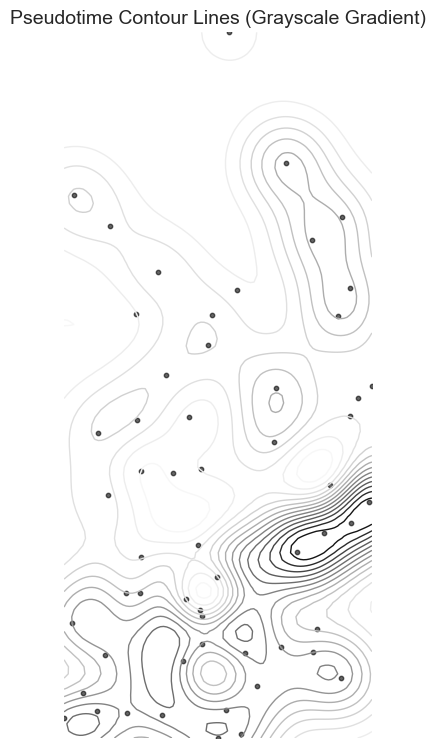

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C

# Drop NaNs
df_clean = df_spatial.dropna(subset=['X', 'Y', 'dpt_paga'])

# Get coordinates and pseudotime
X_coords = df_clean[['X', 'Y']].values
y_pseudotime = df_clean['dpt_paga'].values

# Fit GPR
kernel = C(1.0, (1e-3, 1e3)) * RBF(length_scale=100.0, length_scale_bounds=(1e-2, 1e4))
gpr = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)
gpr.fit(X_coords, y_pseudotime)

# Create a dense grid
x_min, x_max = df_clean['X'].min(), df_clean['X'].max()
y_min, y_max = df_clean['Y'].min(), df_clean['Y'].max()
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))
grid_coords = np.column_stack([xx.ravel(), yy.ravel()])

# Predict pseudotime on the grid
pseudo_grid = gpr.predict(grid_coords).reshape(xx.shape)

# Use a grayscale colormap
gray_cmap = cm.get_cmap('Greys')

# Plot contour lines with a gray gradient
fig, ax = plt.subplots(figsize=(10, 8))
contour = ax.contour(xx, yy, pseudo_grid, levels=15, cmap=gray_cmap, linewidths=1)

# Optional: scatter input ROIs
ax.scatter(df_clean['X'], df_clean['Y'], color='black', s=10, alpha=0.6)

# Custom aesthetics
ax.invert_yaxis()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.xaxis.set_ticks([])
ax.yaxis.set_ticks([])
ax.set_aspect('equal')

ax.set_title('Pseudotime Contour Lines (Grayscale Gradient)', fontsize=14)
plt.tight_layout()
plt.show()



In [24]:
import pandas as pd
import numpy as np

# Function to calculate Euclidean distance
def calculate_distance(x1, y1, x2, y2):
    return np.sqrt((x1 - x2)**2 + (y1 - y2)**2)

# Define the reference roi_id and get its coordinates
reference_roi_id = first_seg
reference_point = df_scatter[df_scatter['roi_id'] == reference_roi_id].iloc[0]

# Initialize a list to store the results
results = []

# Create a set to track visited points
visited = set()

# Add the initial reference point to the visited set
visited.add(reference_point.name)

# Initialize cumulative distance
cumulative_distance = 0

# Iteratively find the closest point and update the reference point
current_point = reference_point
while len(visited) < len(df_scatter):
    distances = []
    for index, row in df_scatter.iterrows():
        if index not in visited:
            dist = calculate_distance(current_point['X'], current_point['Y'], row['X'], row['Y'])
            distances.append((dist, index))
    
    # Find the closest unvisited point
    min_distance, closest_point_index = min(distances, key=lambda x: x[0])
    
    # Update cumulative distance
    cumulative_distance += min_distance
    
    # Update the results
    results.append({
        'current_point_index': current_point.name,
        'closest_point_index': closest_point_index,
        'min_distance': min_distance,
        'cumulative_distance': cumulative_distance
    })
    
    # Update the current point and mark it as visited
    current_point = df_scatter.loc[closest_point_index]
    visited.add(closest_point_index)

# Add the last point to the results
results.append({
    'current_point_index': current_point.name,
    'closest_point_index': None,
    'min_distance': None,
    'cumulative_distance': cumulative_distance
})

# Reorder df_spatial according to the results
order = [reference_point.name] + [res['closest_point_index'] for res in results if res['closest_point_index'] is not None]
df_spatial_ordered = df_scatter.loc[order].reset_index(drop=True)

# Add cumulative distances to df_spatial_ordered
cumulative_distances = [res['cumulative_distance'] for res in results]
df_spatial_ordered['cumulative_distance'] = cumulative_distances
df_spatial_ordered

,roi_id,X,Y,Height,Width,segment,architectures,X_umap,Y_umap,dpt_paga,distance_to_first_seg,cumulative_distance
0,45,33065,48231,1832,1435,Segment 1,glandular dense,11.631609,8.117100,0.000000,0.000000,2503.369330
1,78,33108,50734,1888,1503,Segment 1,solid,11.986410,9.129993,0.189959,2503.369330,3968.919397
2,2,34559,50528,1848,1456,Segment 1,glandular dense,12.032163,8.512710,0.119493,2740.117698,5511.878891
3,3,35641,49428,1854,1544,Segment 1,solid,11.653601,8.719904,0.168883,2840.525480,8599.609773
4,4,38712,49749,1780,1518,Segment 1,glandular infiltrated,11.293482,5.821786,0.827745,5847.472360,12930.902882
5,7,36562,53509,1821,1454,Segment 1,glandular dense,11.631324,9.347574,0.123332,6331.373706,15339.206227
6,1,36889,55895,1731,1501,Segment 1,glandular infiltrated,10.951429,5.424125,0.810574,8565.037770,18234.970030
7,26,34591,57657,1665,1603,Segment 1,glandular infiltrated,11.519912,4.097395,0.812422,9548.725151,20335.015981
8,8,32638,56885,1850,1565,Segment 1,fragmented,11.858112,5.026975,0.774875,8664.527973,22994.924251
9,79,31692,54399,1873,1622,Segment 1,glandular dense,10.118422,4.623920,0.839770,6318.967716,24612.107604


## Plot Pseudotime value across spatial clusters 

meta NOT subset; don't know how to subset; dropped


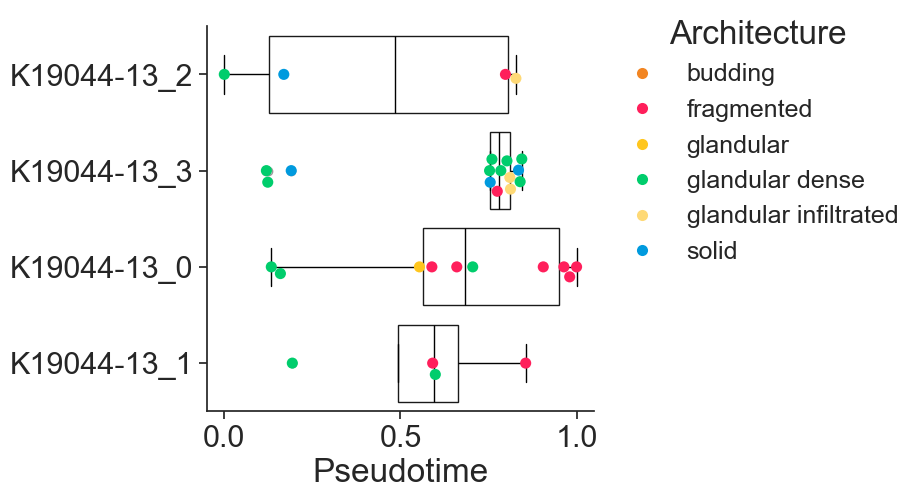

In [40]:
architecture_order = ['fragmented', 'solid', 'glandular dense', 'glandular', 'glandular infiltrated', 'budding' ]

import matplotlib

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

sns.set(font_scale = 2)
sns.set_style("white")

sns.set_style('white', rc={
    'xtick.bottom': True,
    'ytick.left': True,
})
plt.rcParams["figure.figsize"] = (5,5)

g=sns.boxplot(data=df_scatter, 
              y='spatial_cluster', 
              x='dpt_paga', 
              color='w',
                boxprops=dict(linewidth=1, edgecolor='k'),  # Set edgecolor to black
                medianprops=dict(color='black', linewidth=1),
              )
for median in g.lines[:]:
    median.set_color('black')  # Change the color of the median line
    median.set_linewidth(1)  # Change

sns.swarmplot(data=df_scatter, 
              y='spatial_cluster', 
              x='dpt_paga', 
              hue='architectures', 
              palette=architecture_colormap,
              size=8,
    # order=architecture_order,
      c='k')
plt.ylabel('')
plt.xlabel('Pseudotime')
sns.despine()


plt.legend(loc='center left', 
            title='Architecture', 
            bbox_to_anchor=(1.0, 0.7), 
            prop={'size': 18}, 
            frameon=False)


OUT_DIR = r'C:\Users\fbertil\CRC Figures\Figure3\pseudotime'
out_path = os.path.join(OUT_DIR, f'peudotime_across_sc_{patient_id}.pdf')
plt.savefig(out_path, format='pdf', bbox_inches='tight')

## Plot Pseudotime value across architectures

meta NOT subset; don't know how to subset; dropped


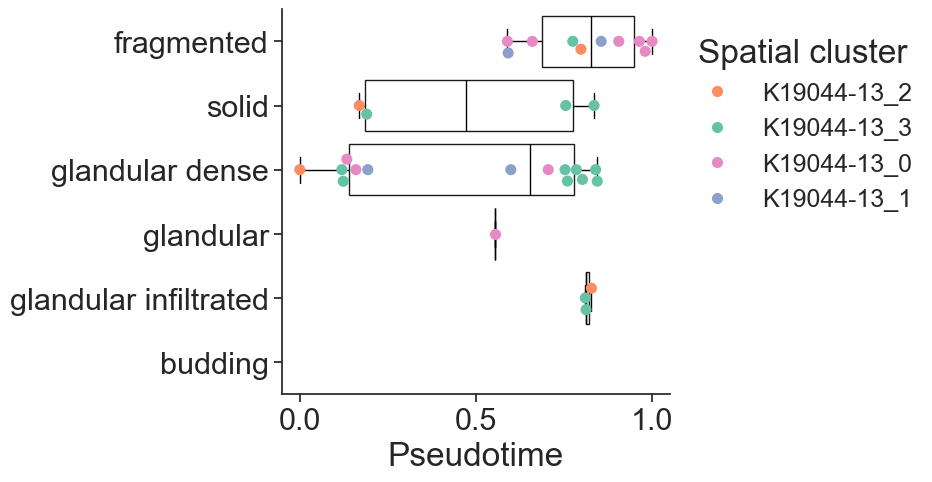

In [41]:
architecture_order = ['fragmented', 'solid', 'glandular dense', 'glandular', 'glandular infiltrated', 'budding' ]
spatial_clusts = df_spatial['spatial_cluster'].unique()
spatial_cluster_colormap = { sc : c for sc, c in zip(spatial_clusts, sns.color_palette('Set2')) }
import matplotlib

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

sns.set(font_scale = 2)
sns.set_style("white")

sns.set_style('white', rc={
    'xtick.bottom': True,
    'ytick.left': True,
})
plt.rcParams["figure.figsize"] = (5,5)

g=sns.boxplot(data=df_scatter, 
              y='architectures', 
              order=architecture_order,
              x='dpt_paga', 
              color='w',
                boxprops=dict(linewidth=1, edgecolor='k'),  # Set edgecolor to black
                medianprops=dict(color='black', linewidth=1),
              )
for median in g.lines[:]:
    median.set_color('black')  # Change the color of the median line
    median.set_linewidth(1)  # Change

sns.swarmplot(data=df_scatter, 
              y='architectures', 
              x='dpt_paga', 
              order=architecture_order,
              hue='spatial_cluster', 
              palette=spatial_cluster_colormap,
              size=8,
    # order=architecture_order,
      c='k')
plt.ylabel('')
plt.xlabel('Pseudotime')
sns.despine()


plt.legend(loc='center left', 
            title='Spatial cluster', 
            bbox_to_anchor=(1.0, 0.7), 
            prop={'size': 18}, 
            frameon=False)


OUT_DIR = r'C:\Users\fbertil\CRC Figures\Figure3\pseudotime'
out_path = os.path.join(OUT_DIR, f'peudotime_across_architectures_{patient_id}.pdf')
plt.savefig(out_path, format='pdf', bbox_inches='tight')

## Plot changes in spatial clusters and architecture types along pseudotime, profiled within consecutive sliding windows

    glandular dense  budding  fragmented  glandular  glandular infiltrated  \
0               1.0      NaN         NaN        NaN                    NaN   
1               0.8      NaN         NaN        NaN                    NaN   
2               0.6      NaN         NaN        NaN                    NaN   
3               0.6      NaN         NaN        NaN                    NaN   
4               0.4      NaN         NaN        0.2                    NaN   
5               0.2      NaN         0.2        0.2                    NaN   
6               0.2      NaN         0.4        0.2                    NaN   
7               0.4      NaN         0.4        0.2                    NaN   
8               0.2      NaN         0.6        0.2                    NaN   
9               0.4      NaN         0.6        NaN                    NaN   
10              0.6      NaN         0.4        NaN                    NaN   
11              0.6      NaN         0.2        NaN             

meta NOT subset; don't know how to subset; dropped


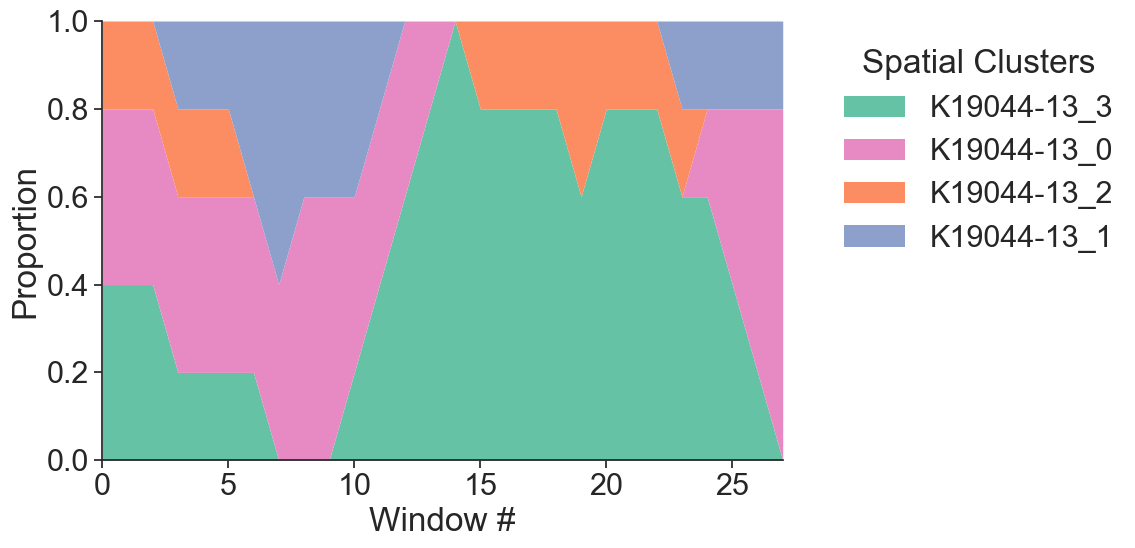

In [44]:
import matplotlib.pyplot as plt

# Custom colormap for architectures
architecture_colors = {
    'solid': '#009ADE',
    'glandular dense': '#00CD6C',
    'glandular': '#FFC61E',
    'glandular infiltrated': '#FED976',
    'budding': '#F28522',
    'fragmented': '#FF1F5B'
}

spatial_clusts = df_spatial['spatial_cluster'].unique()
spatial_cluster_colors = { sc : c for sc, c in zip(spatial_clusts, sns.color_palette('Set2')) }

def plot_stacked_area_distribution_with_custom_colormap(df, window_size, step_size):
    df = df.sort_values(by='dpt_paga')
    start = 0
    end = window_size
    step = 0
    
    architectures_steps = []
    spatial_clusters_steps = []
    steps = []
    
    # Collect proportions for each step
    while end <= len(df):
        window = df.iloc[start:end]
        
        # Get normalized counts for architectures and spatial clusters
        architecture_counts = window['architectures'].value_counts(normalize=True).to_dict()
        spatial_counts = window['spatial_cluster'].value_counts(normalize=True).to_dict()
        
        architectures_steps.append(architecture_counts)
        spatial_clusters_steps.append(spatial_counts)
        steps.append(step)
        
        # Move the window
        start += step_size
        end += step_size
        step += 1
    
    # Convert to DataFrames to easily handle missing values (not all architectures or clusters may be present in every step)

    architectures_df = pd.DataFrame(architectures_steps, index=steps).fillna(0)
    spatial_clusters_df = pd.DataFrame(spatial_clusters_steps, index=steps).fillna(0)
    architectures_df = architectures_df.replace(0, np.nan)
    print(architectures_df)
    # Plot architecture distributions over steps as stacked area plot with custom colormap

    # sns.set_style('white', rc={
    #     'xtick.bottom': True,
    #     'ytick.left': True,
    # })
    # ax = architectures_df.plot(kind='area', stacked=True, figsize=(12, 6), alpha=1, linewidth=0,
    #                            color=[architecture_colors.get(col, '#333333') for col in architectures_df.columns])
    

    
    # plt.ylim(0, 1)  # Start y-axis at 0 and go to 1 for proportion
    # plt.xlim(steps[0], steps[-1])  # Set x-axis limit from first to last step
    # plt.gca().margins(x=0)  # Remove horizontal margins
    # sns.despine()
    # # plt.title('Architectures Distribution Over Steps (Stacked)')
    # plt.ylabel('Proportion')
    # plt.xlabel('Window #')
    # plt.legend(title='Architectures', bbox_to_anchor=(1.05, 1), loc='upper left', frameon=False)
    # plt.tight_layout()
    # # plt.show()


    
    # OUT_DIR = r'C:\Users\fbertil\CRC Figures\Figure3\pseudotime'
    # out_path = os.path.join(OUT_DIR, f'pseudotime_evolution_archi_{patient_id}.pdf')
    # plt.savefig(out_path, format='pdf', bbox_inches='tight')

    sns.set_style('white', rc={
        'xtick.bottom': True,
        'ytick.left': True,
    })

    spatial_clusters_df.plot(kind='area', stacked=True, figsize=(12, 6), alpha=1,linewidth=0,
                             color=[spatial_cluster_colors.get(col, '#333333') for col in spatial_clusters_df])
    
    # Remove gap between x=0 and y=0
    plt.ylim(0, 1)  # Start y-axis at 0 and go to 1 for proportion
    plt.xlim(steps[0], steps[-1])  # Set x-axis limit from first to last step
    plt.gca().margins(x=0)  # Remove horizontal margins
    sns.despine()
    # plt.title('Spatial Clusters Distribution Over Steps (Stacked)')
    plt.ylabel('Proportion')
    plt.xlabel('Window #')
    plt.legend(title='Spatial Clusters', bbox_to_anchor=(1.05, 1), loc='upper left', frameon=False)
    plt.tight_layout()
    # plt.show()

    OUT_DIR = r'C:\Users\fbertil\CRC Figures\Figure3\pseudotime'
    out_path = os.path.join(OUT_DIR, f'pseudotime_evolution_sc_{patient_id}.pdf')
    plt.savefig(out_path, format='pdf', bbox_inches='tight')


# Define window size and step size
window_size = 5  # Number of data points in each window
step_size = 1   # Step size for sliding window

# Plot stacked area distributions over steps with custom colormap
plot_stacked_area_distribution_with_custom_colormap(df_scatter, window_size, step_size)



# Spatial projection of spatial cluster

In [33]:
spatial_clusts = df_spatial['spatial_cluster'].unique()
spatial_cluster_colormap = { sc : c for sc, c in zip(spatial_clusts, sns.color_palette('Set2')) }

# Spatial projection of architectures with pseudotime

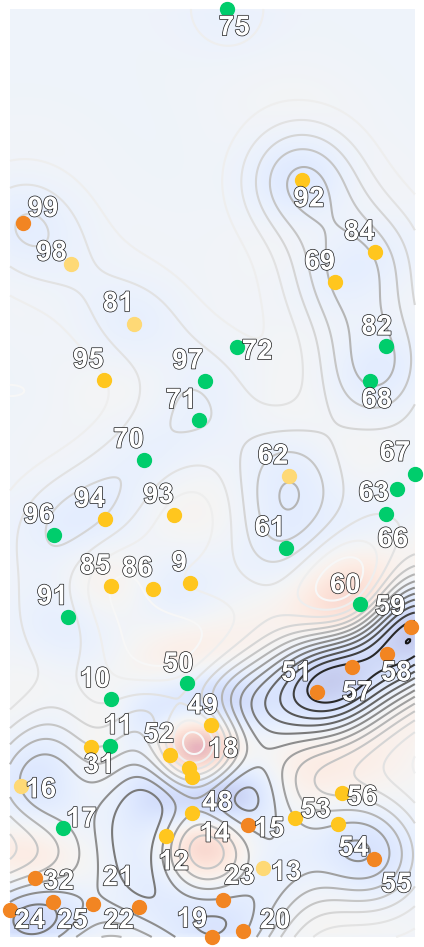

In [133]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as PathEffects
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel
import seaborn as sns
import math
import matplotlib

# Optional adjust_text fallback (no arrows)
try:
    from adjustText import adjust_text
    def do_adjust_text(texts):
        adjust_text(texts)
except ImportError:
    def do_adjust_text(texts):
        pass

# --- Parameters ---
scale_factor = 1.0       # display scaling
arrow_factor = 3000000   # arrow‐length multiplier
step = 15                # draw every Nth arrow

# --- Setup plotting ---
sns.set(font_scale=2)
sns.set_style("white")
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

fig, ax = plt.subplots(figsize=(10, 10))
texts = []

# --- Draw ROIs and labels (in display units) ---
for row in df_spatial.itertuples():
    x0 = row.X * scale_factor
    y0 = row.Y * scale_factor
    ax.scatter(
        x0, y0,
        color=architecture_colormap[row.architectures],
        s=100, alpha=1, zorder=3
    )
    if not math.isnan(row.dpt_paga):
        txt = ax.text(
            x0 , 
            y0 ,
            f'{row.roi_id}',
            fontsize=20, fontweight='bold',
            color='white', ha='center', va='center',
            zorder=3
        )
        txt.set_path_effects([PathEffects.withStroke(linewidth=1, foreground='k')])
        texts.append(txt)

# --- Fit GPR on original coords ---
df_clean = df_spatial.dropna(subset=['X','Y','dpt_paga'])
Xc = df_clean[['X','Y']].values
yc = df_clean['dpt_paga'].values
kernel = ConstantKernel(1.0, (1e-3,1e3)) * RBF(100.0, (1e-2,1e4))
gpr = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)
gpr.fit(Xc, yc)


# --- Build a dense grid in original coords ---
x_min, x_max = df_clean['X'].min(), df_clean['X'].max()
y_min, y_max = df_clean['Y'].min(), df_clean['Y'].max()
nx, ny = 500, 500
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, nx),
    np.linspace(y_min, y_max, ny)
)
coords = np.column_stack([xx.ravel(), yy.ravel()])

# --- Predict pseudotime & compute gradient in original units ---
pseudo_grid = gpr.predict(coords).reshape(xx.shape)
dx_spacing = (x_max - x_min) / (nx - 1)
dy_spacing = (y_max - y_min) / (ny - 1)
dy, dx = np.gradient(pseudo_grid, dy_spacing, dx_spacing)

# --- Compute divergence (sources/sinks) ---
divergence = np.gradient(dx, axis=1) + np.gradient(dy, axis=0)

# --- Prepare display‐scaled grid for plotting ---
xx_plot = xx * scale_factor
yy_plot = yy * scale_factor
x_min_pl, x_max_pl = x_min*scale_factor, x_max*scale_factor
y_min_pl, y_max_pl = y_min*scale_factor, y_max*scale_factor

# --- Plot grayscale contour lines ---
ax.contour(
    xx_plot, yy_plot, pseudo_grid,
    origin='lower',
    levels=15, cmap='Greys', linewidths=1.5, zorder=2
)

# --- Plot divergence heatmap (sources in red, sinks in blue) ---
ax.imshow(
    divergence,
    extent=(x_min_pl, x_max_pl, y_min_pl, y_max_pl),
    origin='lower',
    cmap='coolwarm',
    alpha=0.3,
    zorder=1
)


# --- Final formatting & unclipped view ---
do_adjust_text(texts)
ax.invert_yaxis()
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks([]); ax.set_yticks([])
ax.set_aspect('equal')

# 1) add a small margin so edge‐touching artists are fully shown
ax.margins(0.05)

# 2) disable clipping on all collections (scatter points, contours, etc.)
for coll in ax.collections:
    coll.set_clip_on(False)

plt.tight_layout()
out_path = os.path.join(r'C:\Users\fbertil\CRC Figures\contours_plot_architectures.pdf')
plt.savefig(out_path, format='pdf', bbox_inches='tight')
plt.show()


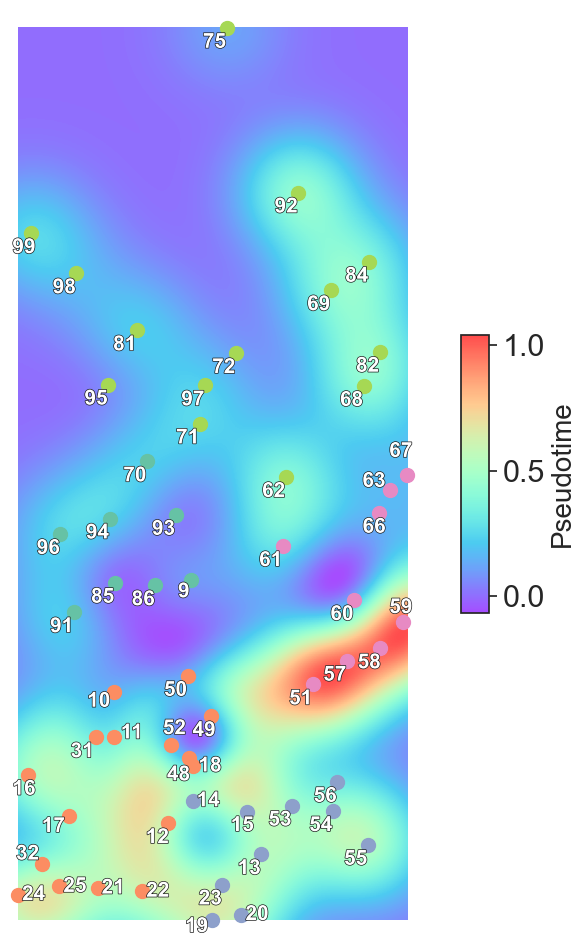

In [136]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as PathEffects
import matplotlib
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel
import seaborn as sns
import math

# Optional adjust_text fallback (no arrows)
try:
    from adjustText import adjust_text
    def do_adjust_text(texts):
        adjust_text(texts)
except ImportError:
    def do_adjust_text(texts):
        pass

# --- Parameters ---
scale_factor = 1.0
nx, ny = 500, 500

# --- Plot styling ---
sns.set(font_scale=2)
sns.set_style("white")
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

fig, ax = plt.subplots(figsize=(10, 10))
texts = []

# --- Fit GPR on pseudotime ---
df_clean = df_spatial.dropna(subset=['X','Y','dpt_paga'])
Xc = df_clean[['X','Y']].values
yc = df_clean['dpt_paga'].values
kernel = ConstantKernel(1.0, (1e-3,1e3)) * RBF(100.0, (1e-2,1e4))
gpr = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)
gpr.fit(Xc, yc)

# --- Build grid & predict ---
x_min, x_max = df_clean['X'].min(), df_clean['X'].max()
y_min, y_max = df_clean['Y'].min(), df_clean['Y'].max()
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, nx),
    np.linspace(y_min, y_max, ny)
)
coords = np.column_stack([xx.ravel(), yy.ravel()])
pseudo_grid = gpr.predict(coords).reshape(xx.shape)

# --- Plot pseudotime heatmap ---
extent = (
    x_min * scale_factor,
    x_max * scale_factor,
    y_min * scale_factor,
    y_max * scale_factor
)
im = ax.imshow(
    # np.flipud(pseudo_grid),    # flip so origin='lower'
    pseudo_grid,
    extent=extent,
    cmap='rainbow',
    alpha=0.7,
    origin='lower',
    zorder=1
)

# --- Overlay spatial clusters & labels with no clipping ---
for row in df_spatial.itertuples():
    x0, y0 = row.X * scale_factor, row.Y * scale_factor
    ax.scatter(
        x0, y0,
        color=spatial_cluster_colormap[row.spatial_cluster],
        s=100, alpha=1,
        zorder=3,
        clip_on=False
    )
    if not math.isnan(row.dpt_paga):
        txt = ax.text(
            x0, y0, f'{row.roi_id}',
            fontsize=15, fontweight='bold',
            color='white', ha='center', va='center',
            zorder=4,
            clip_on=False
        )
        txt.set_path_effects([PathEffects.withStroke(linewidth=1, foreground='k')])
        texts.append(txt)

# --- Colorbar for pseudotime ---
cbar = fig.colorbar(im, ax=ax, shrink=0.3, aspect=10)
cbar.set_label('Pseudotime', fontsize=20)

# --- Explicitly expand axis limits so markers at edges aren’t cut off ---
pad_x = 0.02 * (x_max - x_min) * scale_factor
pad_y = 0.02 * (y_max - y_min) * scale_factor
ax.set_xlim(x_min*scale_factor - pad_x, x_max*scale_factor + pad_x)
ax.set_ylim(y_max*scale_factor + pad_y, y_min*scale_factor - pad_y)  # inverted Y

# --- Final formatting ---
do_adjust_text(texts)
# ax.invert_yaxis()
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks([]); ax.set_yticks([])
ax.set_aspect('equal')
ax.margins(0.05)

# plt.title(patient_id)
plt.tight_layout()

# (Optional) Save to file:
out_path = r'C:\Users\fbertil\CRC Figures\spatial_pseudotime_overlay.pdf'
# plt.savefig(out_path, format='pdf', bbox_inches='tight')

plt.show()


# Plot gene expression vs pseudotime

In [70]:
from geomxlib import *

DIR = r'C:\Users\fbertil\CRC Figures\geomx analysis\data'
EXPRS_PATH = os.path.join(DIR, 'geomx_crc_dataset.h5ad')
adata = sc.read(EXPRS_PATH)
# Load tumor (segment1 = tumor)
adata= adata[adata.obs['segment'] == 'Segment 1'] 

adata = scanpy_preprocessing(adata, 
                             layer='processed',
                             n_neighbors=30,
                             n_pcs=30)

adata = adata[adata.obs['patient_id']==patient_id]
sc.pp.scale(adata)


c:\ProgramData\anaconda3\envs\bioinfo\lib\site-packages\scanpy\preprocessing\_scale.py:316: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


In [71]:
from sklearn.neighbors import NearestNeighbors
import networkx as nx
import community as community_louvain

def louvain_clustering(adata, patient_id_col, x_col, y_col):
    # Get unique patient IDs
    patient_ids = adata.obs[patient_id_col].unique()
    
    # Prepare a Series to store combined cluster labels
    combined_clusters = pd.Series(index=adata.obs.index, dtype='object')
    
    for patient_id in patient_ids:
        # Subset the data for the current patient
        subset = adata[adata.obs[patient_id_col] == patient_id]
        
        # Extract the spatial coordinates
        coords = subset.obs[[x_col, y_col]].values
        
        # Create a nearest neighbors graph
        neighbors = NearestNeighbors(n_neighbors=10).fit(coords)
        graph = neighbors.kneighbors_graph(coords)
        
        # Convert the neighbors graph to a NetworkX graph
        G = nx.from_scipy_sparse_matrix(graph)
        
        # Run Louvain clustering
        partition = community_louvain.best_partition(G)
        
        # Combine patient ID with cluster value
        combined_cluster_labels = {idx: f"{patient_id}_{cluster}" for idx, cluster in partition.items()}
        
        # Store the combined cluster labels
        clusters_subset = pd.Series(combined_cluster_labels, name='combined_cluster')
        clusters_subset.index = subset.obs.index
        combined_clusters.update(clusters_subset)
    
    # Add the combined clusters back to the original AnnData object
    adata.obs['combined_cluster'] = combined_clusters
    
    return adata

adata = louvain_clustering(adata, 'patient_id', 'X', 'Y')

C:\Users\fbertil\AppData\Local\Temp\ipykernel_26428\2666108761.py:24: DeprecationWarning: 

The scipy.sparse array containers will be used instead of matrices
in Networkx 3.0. Use `from_scipy_sparse_array` instead.
  G = nx.from_scipy_sparse_matrix(graph)


In [74]:
patient_idx = adata.obs['patient_id']==patient_id
var_df = adata[:].to_df()
var_df.iloc[:, :] = adata.X
var_df = var_df.loc[patient_idx]
# var_df
df_spatial2 = pd.concat([df_spatial, var_df], axis=1)
df_spatial2['spatial_clusters'] = adata.obs['combined_cluster']

# df_spatial2

In [47]:
DIR = r'E:\CRC_slides'
GENE_SETS_PATH = os.path.join(DIR, 'gene_sets.json')

with open(GENE_SETS_PATH, 'r') as file:
    gene_sets = json.load(file)

meta NOT subset; don't know how to subset; dropped


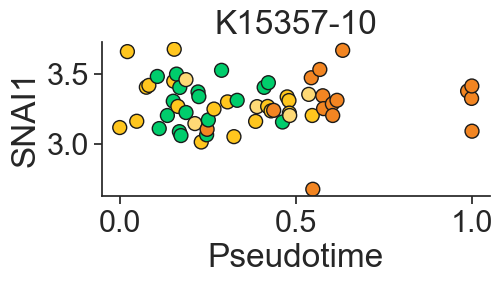

In [50]:
df_plot = df_spatial2.dropna()
df_plot = df_plot.sort_values(by='dpt_paga')
architecture_values = df_plot['architectures'].values
colors = [architecture_colormap[v] for v in architecture_values]

plt.figure(figsize=(5,2))
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

sns.set_style('white', rc={
    'xtick.bottom': True,
    'ytick.left': True,
})

plt.title(patient_id)
RNA = 'SNAI1'
plt.scatter(df_plot['dpt_paga'].values, df_plot[RNA].values, s=100, c=colors,edgecolors='k')


plt.xlabel('Pseudotime')
plt.ylabel(RNA)
sns.despine()

plt.savefig(r'C:\Users\fbertil\CRC Figures\Figure3\SNAI1_pseudotime.pdf', format='pdf', bbox_inches='tight')